In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
droppers = pd.read_csv('droppers.csv')

droppers.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,DATES
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,254712129778,NaN
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com,254720925163,NaN
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com,254724589595,NaN
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com,254719750454,NaN
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com,254722139396,NaN


In [3]:
droppers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   products_viewed    420 non-null    int64  
 1   view_events        420 non-null    int64  
 2   sales_since_sep30  420 non-null    int64  
 3   viewed_per_sale    420 non-null    float64
 4   all_sales_alltime  420 non-null    int64  
 5   quotes_alltime     420 non-null    int64  
 6   user_name          420 non-null    object 
 7   county             419 non-null    object 
 8   email              420 non-null    object 
 9   phone_number       420 non-null    int64  
 10  DATES              0 non-null      float64
dtypes: float64(2), int64(6), object(3)
memory usage: 36.2+ KB


In [4]:
droppers = droppers.drop(columns=['DATES','phone_number'])

droppers.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com


In [5]:
droppers.value_counts(['user_name'])

user_name                   
A PLAN Insurance Brokers Ltd    1
Mark Kemei                      1
Moureen Munyiva                 1
Moseti Nyachio Justine          1
Moses Okal                      1
                               ..
Faith Mukavale                  1
FREDRICK OTIENO                 1
FLORENCE MUTHONI NJENGA         1
FELIX BARNGETUNY                1
joseph gatu                     1
Name: count, Length: 420, dtype: int64

#### Policies created since September 30th compared to sales done before September 30th

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

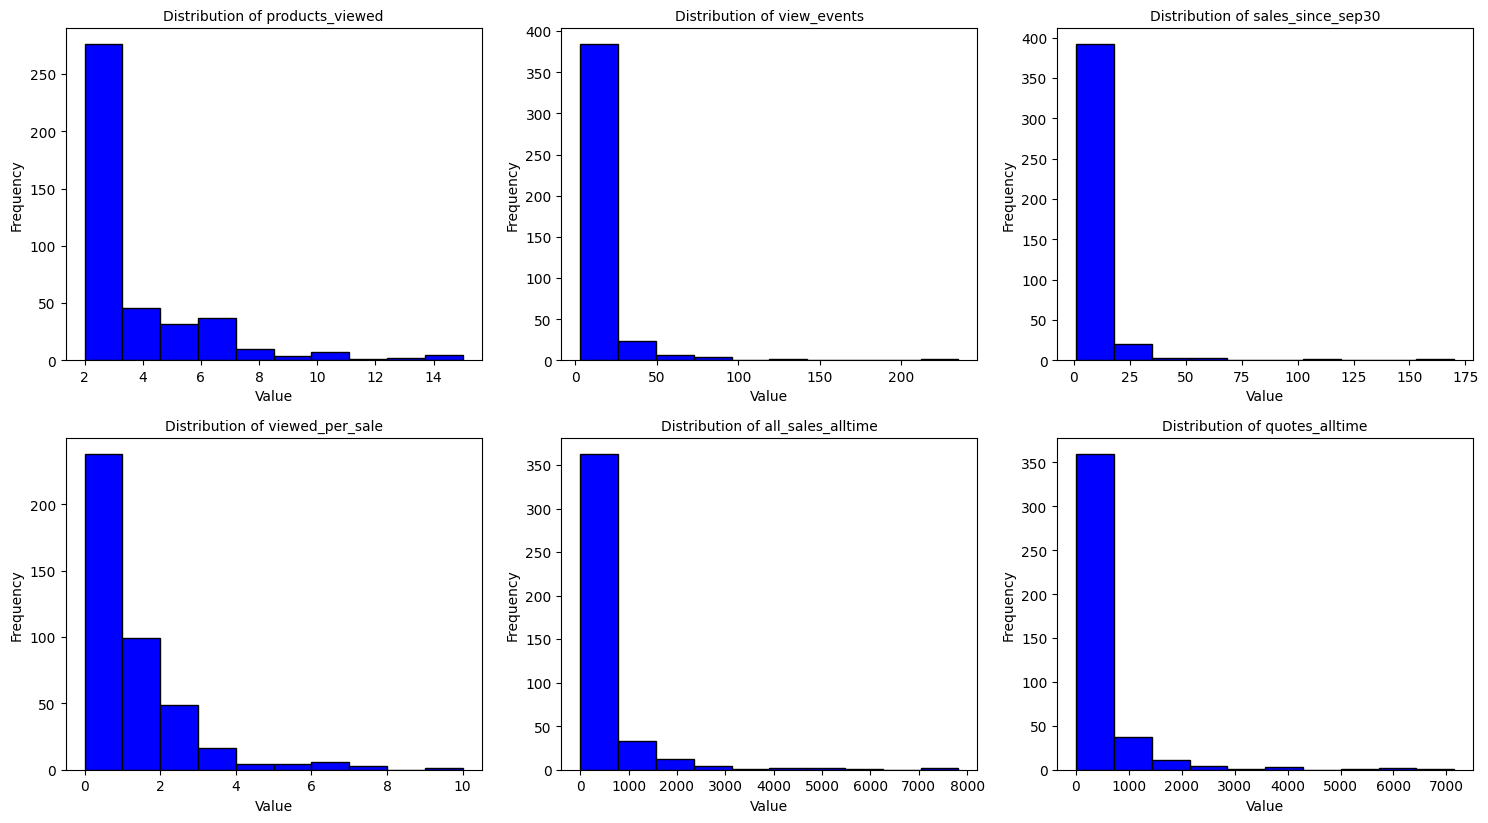

In [17]:
cols = [
    'products_viewed',
    'view_events',
    'sales_since_sep30',
    'viewed_per_sale',
    'all_sales_alltime',
    'quotes_alltime'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(droppers[col].dropna(), bins=10,
                 color='blue', edgecolor='black')
    axes[i].set_title(f'Distribution of {col}', fontsize=10)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Hide the three unused plots
for i in range(len(cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [19]:
droppers['sales_before_sept30'] = droppers['all_sales_alltime'] - droppers['sales_since_sep30']

droppers.head(10)

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,sales_before_sept30
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,1
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com,0
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com,168
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com,7
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com,1
5,12,43,2,6.0,4591,3655,Edvan Insurance Agency,Nairobi City,edvanagency@gmail.com,4589
6,6,17,1,6.0,68,87,Tim Gatehi,Nairobi City,timgatehit@gmail.com,67
7,6,16,1,6.0,263,240,Kevin Kwanusu,Nairobi City,kipropkevin93@gmail.com,262
8,6,20,1,6.0,106,120,Phillis Comfort Ngosenywe,Nairobi City,comphy81@gmail.com,105
9,6,14,1,6.0,218,232,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,217


#### Percentile ranks (0-1). A big gap means an agent was a top seller, but now isn't 

In [23]:
droppers['rank_lifetime'] = droppers['all_sales_alltime'].rank(pct=True)
droppers['rank_recent'] = droppers['sales_since_sep30'].rank(pct=True)
droppers['rank_gap'] = (droppers['rank_lifetime'] - droppers['rank_recent']) *100

In [24]:
median_views = droppers['view_events'].median()
print(f"The median number of view events is: {median_views}")

median_sales = droppers['sales_since_sep30'].median()
print(f"The median number of sales since September 30 is: {median_sales}")

The median number of view events is: 9.0
The median number of sales since September 30 is: 4.0


In [29]:
conditions = [
    droppers['sales_before_sept30'] == 0,  #new agent
    droppers['rank_gap'] > 0,  #declining agent/ slowing vs own history 
    (droppers['view_events'] > median_views) & (droppers['sales_since_sep30'] <= median_sales),  #high view low sales
    droppers['sales_since_sep30'] > median_sales,  #high sales/producing

]

labels = [
    'New Agent',
    'Slowing vs Own History',
    'Browsin, not producing',
    'Producing'
]

droppers['status'] = np.select(conditions, labels, default='Low, but steady')

droppers.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,sales_before_sept30,rank_gap,rank_lifetime,rank_recent,status
0,10,22,1,10.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,1,-6.904762,0.008333,0.077381,"Browsin, not producing"
1,14,84,2,7.0,2,5,Catherine Kagendo Kinyua,Nairobi City,kinyuakcatherine@gmail.com,0,-22.857143,0.008333,0.236905,New Agent
2,7,17,1,7.0,169,152,MARY WANGUI WAMBUI,Nairobi City,wambuikui17@gmail.com,168,39.642857,0.473810,0.077381,Slowing vs Own History
3,7,22,1,7.0,8,21,PETER KURIA,Nairobi City,peterkuria114@gmail.com,7,-3.095238,0.046429,0.077381,"Browsin, not producing"
4,13,37,2,6.5,3,20,Justus Muvila,Nairobi City,justusmuvila@gmail.com,1,-21.904762,0.017857,0.236905,"Browsin, not producing"


### Aggregation of each groups (%) of  total sales in each period

In [32]:
order = ['Slowing vs Own History',
         'Browsin, not producing',
         'Low but steady',
         'Producing',
         'New Agent']        


In [36]:
summary = (
    droppers.groupby('status')[['sales_before_sept30', 'sales_since_sep30']].sum().reindex(order)  
)

print(summary)

share = summary/ summary.sum() *100
print(share.round(1))

                        sales_before_sept30  sales_since_sep30
status                                                        
Slowing vs Own History             109658.0             1016.0
Browsin, not producing               1628.0               93.0
Low but steady                          NaN                NaN
Producing                           73313.0             1691.0
New Agent                               0.0                5.0
                        sales_before_sept30  sales_since_sep30
status                                                        
Slowing vs Own History                 59.4               36.2
Browsin, not producing                  0.9                3.3
Low but steady                          NaN                NaN
Producing                              39.7               60.3
New Agent                               0.0                0.2
